# Seoul bike demand: evaluating an hourly planning model

Planning bike availability requires an estimate of how rental demand varies through the day. This project asks whether a model improves that estimate over a simple calendar rule, and where its errors would constrain operational use. The data describe citywide hourly rentals; they cannot tell a planner how many bikes to move between particular stations or how much unmet demand exists.

The decision is whether to advance a model to further testing under a clear input-availability contract. Random Forest, selected using earlier validation, lowers final operating-hour RMSE by **21.66%** compared with the hour-weekday baseline. Its final RMSE is **377.83** and MAE is **275.16 bikes/hour**. It still underpredicts by **205.66 bikes/hour on average**; MAE reaches **554.79** in the retrospective high-demand segment. Those misses belong beside the improvement when assessing the recommendation.

The result uses observed weather for the hour being predicted. It supports conditional historical prediction, and has not established a day-ahead planning forecast. A separately tuned calendar-only forest records RMSE **468.40**, showing why the weather-availability question matters without isolating a causal weather effect.

Read the analysis in this order: demand patterns, comparison with a planning baseline, error concentration, input availability, and the next decision. Detailed evaluation settings and source-review corrections follow the recommendation in the technical appendix.

## Data and scope of the decision

The public UCI Seoul Bike Sharing Demand file has **8,760 hourly records** from 1 December 2017 to 30 November 2018. All raw rows and operating-status values are preserved. Models learn from **6,528 operating hours** before September 2018 and receive the same **1,937 operating hours** in the September to November test. Three earlier monthly validation windows select the candidate. The 295 closed hours remain in the data; all-hours reporting uses a separate known-closure assumption.

The notebook checks the bundled data before modelling. Nulls, duplicates and rare-weather flags have explicit treatment. Visibility is recorded in 10-metre units. Completed rentals are the target, so observed counts may be constrained by bike availability. No station inventory, operating costs or agreed error tolerance is supplied.

Dataset: [UCI Seoul Bike Sharing Demand](https://archive.ics.uci.edu/dataset/560/seoul+bike+sharing+demand), DOI [10.24432/C5F62R](https://doi.org/10.24432/C5F62R), CC BY 4.0. The analysis adapts the group work of Thanh Nguyen, Anh Dang, Nhat Nam Phan and Khoa Nguyen.

## My contribution: model building and evaluation

I focused on building and evaluating the kNN and Random Forest models. I selected and compared evaluation metrics, particularly RMSE and MAE, to assess prediction errors and support model selection. I also examined bootstrapping and bagging in Random Forest.
My contribution connected these modelling choices to hourly bike-demand planning, considering both prediction accuracy and the limitations affecting practical use.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import platform
import time
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, make_scorer
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

get_ipython().run_line_magic("matplotlib", "inline")
SEED = 123
STARTED_AT = datetime.now(timezone.utc).isoformat()
STARTED_TIMER = time.perf_counter()
# ROOT locates the project; RESULTS and FIGURES store the files created below.
ROOT = Path.cwd()
assert (ROOT / "data" / "SeoulBikeData.csv").exists(), "Run from this project folder."
RESULTS = ROOT / "results"
FIGURES = RESULTS / "figures"
GENERATED = ROOT / ".generated"
GENERATED.mkdir(exist_ok=True)
(GENERATED / "figures").mkdir(exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
PUBLIC_EXPORTS = ['model_metrics.csv', 'test_predictions.csv']
PUBLIC_FIGURES = ['03_model_comparison.png', '04_residual_diagnostics.png']


def artifact_path(name):
    # Keep the review exports public; regenerate other diagnostics locally.
    return (RESULTS if name in PUBLIC_EXPORTS else GENERATED) / name
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
# VERSIONS records this run's packages for reproducibility.
VERSIONS = {name: version(name) for name in
            ["numpy", "pandas", "scikit-learn", "matplotlib", "nbformat", "nbclient", "ipykernel"]}
display(pd.Series(VERSIONS, name="executed_version").to_frame())

def save_figure(name, caption=None):
    # Reuse FIGURES so every chart is saved before it appears in the notebook.
    # Reserve a footer so the exported chart carries its interpretation and limit.
    figure = plt.gcf()
    if caption:
        figure.tight_layout(rect=(0, 0.14, 1, 1))
        figure.text(0.02, 0.025, caption, fontsize=8.5, ha="left", va="bottom", linespacing=1.4)
    directory = FIGURES if name in PUBLIC_FIGURES else GENERATED / "figures"
    plt.savefig(directory / name, bbox_inches="tight", dpi=160)
    plt.show()

,executed_version
numpy,2.3.5
pandas,3.0.1
scikit-learn,1.9.1
matplotlib,3.11.2
nbformat,5.11.1
nbclient,0.11.0
ipykernel,6.29.5


In [2]:
DATA_PATH = ROOT / "data" / "SeoulBikeData.csv"
# DATA_SHA256 checks the bundled file before any transformation or fitting.
DATA_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
EXPECTED_SHA256 = "373339b71a8935d69e9af0abf26a70744632119862eeb3919efb389a7b749c60"
assert DATA_SHA256 == EXPECTED_SHA256, "Bundled raw data changed; inspect and update provenance intentionally."
raw = pd.read_csv(DATA_PATH, encoding="cp1252")
assert raw.shape[1] == 14
# data is the parsed analytical copy; raw retains the original rows and columns.
data = raw.copy()
data.columns = ["date", "rentals", "hour", "temperature_c", "humidity_pct",
                "wind_speed_ms", "visibility_10m", "dew_point_c", "solar_radiation_mjm2",
                "rainfall_mm", "snowfall_cm", "season", "holiday", "functioning_day"]
data["date"] = pd.to_datetime(data["date"], format="%d/%m/%Y", errors="raise")
data["timestamp"] = data["date"] + pd.to_timedelta(data["hour"], unit="h")
data = data.sort_values("timestamp", kind="stable").reset_index(drop=True)
assert len(data) == len(raw) == 8760
assert data["functioning_day"].isin(["Yes", "No"]).all()
assert data["season"].isin(["Winter", "Spring", "Summer", "Autumn"]).all()
assert data["holiday"].isin(["Holiday", "No Holiday"]).all()

# checks collects audit counts; assertions stop modelling if key checks fail.
checks = {
    "rows": len(raw),
    "missing_cells": int(raw.isna().sum().sum()),
    "exact_duplicate_rows": int(raw.duplicated().sum()),
    "duplicate_timestamps": int(data["timestamp"].duplicated().sum()),
    "source_chronological": bool(data["timestamp"].equals(
        pd.to_datetime(raw.iloc[:, 0], format="%d/%m/%Y") + pd.to_timedelta(raw.iloc[:, 2], unit="h"))),
    "invalid_hour_rows": int((~data["hour"].between(0, 23)).sum()),
    "negative_or_fractional_target_rows": int(((data["rentals"] < 0) | (data["rentals"] % 1 != 0)).sum()),
    "humidity_outside_0_to_100_rows": int((~data["humidity_pct"].between(0, 100)).sum()),
    "zero_humidity_rows_retained": int((data["humidity_pct"] == 0).sum()),
    "negative_nonnegative_weather_rows": int((data[["wind_speed_ms", "visibility_10m",
        "solar_radiation_mjm2", "rainfall_mm", "snowfall_cm"]] < 0).any(axis=1).sum()),
    "closed_hours": int((data["functioning_day"] == "No").sum()),
    "closed_hours_with_nonzero_rentals": int(((data["functioning_day"] == "No") & (data["rentals"] != 0)).sum()),
    "first_timestamp": data["timestamp"].min().isoformat(),
    "last_timestamp": data["timestamp"].max().isoformat(),
    "sha256": DATA_SHA256,
}
assert checks["missing_cells"] == checks["exact_duplicate_rows"] == checks["duplicate_timestamps"] == 0
assert checks["invalid_hour_rows"] == checks["negative_or_fractional_target_rows"] == 0
assert checks["humidity_outside_0_to_100_rows"] == checks["negative_nonnegative_weather_rows"] == 0
assert checks["closed_hours_with_nonzero_rentals"] == 0
assert data["timestamp"].diff().dropna().eq(pd.Timedelta(hours=1)).all()
(artifact_path("data_audit.json")).write_text(json.dumps(checks, indent=2), encoding="utf-8")
display(pd.Series(checks, name="audit_result").to_frame())
status_summary = data.groupby("functioning_day")["rentals"].agg(hours="size", mean_rentals="mean", max_rentals="max")
display(status_summary)

,audit_result
rows,8760
missing_cells,0
exact_duplicate_rows,0
duplicate_timestamps,0
source_chronological,True
invalid_hour_rows,0
negative_or_fractional_target_rows,0
humidity_outside_0_to_100_rows,0
zero_humidity_rows_retained,17
negative_nonnegative_weather_rows,0


,hours,mean_rentals,max_rentals
functioning_day,,,
No,295,0.000000,0
Yes,8465,729.156999,3556


## 1. What demand patterns should planning accommodate?

The development data let us inspect the target population before choosing a model. Counts vary by hour, season and weather conditions. A simple planning rule should provide a benchmark; a flexible model must earn its additional complexity by improving later predictions. The following graphs use development operating hours only.

,population,hours,start,end,mean_rentals
0,Development: operating,6528,2017-12-01,2018-08-31 23:00:00,671.310049
1,Final test: operating,1937,2018-09-01,2018-11-30 23:00:00,924.110480
2,Raw: all hours,8760,2017-12-01,2018-11-30 23:00:00,704.602055


,development_IQR_flags,rows_deleted
temperature_c,0,0
humidity_pct,0,0
wind_speed_ms,97,0
visibility_10m,0,0
dew_point_c,0,0
solar_radiation_mjm2,524,0
rainfall_mm,429,0
snowfall_cm,392,0


,rentals,temperature_c,humidity_pct,wind_speed_ms,visibility_10m,dew_point_c,solar_radiation_mjm2,rainfall_mm,snowfall_cm
count,6528.00,6528.00,6528.00,6528.00,6528.00,6528.00,6528.00,6528.00,6528.00
mean,671.31,12.46,57.88,1.80,1396.99,3.59,0.58,0.16,0.08
std,638.22,13.19,20.88,1.06,616.55,14.40,0.89,1.19,0.42
min,2.00,-17.80,0.00,0.00,27.00,-30.60,0.00,0.00,0.00
25%,189.00,1.20,42.00,1.00,881.00,-7.70,0.00,0.00,0.00
50%,424.00,13.60,57.00,1.60,1610.00,4.70,0.02,0.00,0.00
75%,997.25,23.72,74.00,2.40,1987.00,16.30,0.93,0.00,0.00
max,3556.00,39.40,98.00,7.40,2000.00,27.20,3.52,35.00,5.10


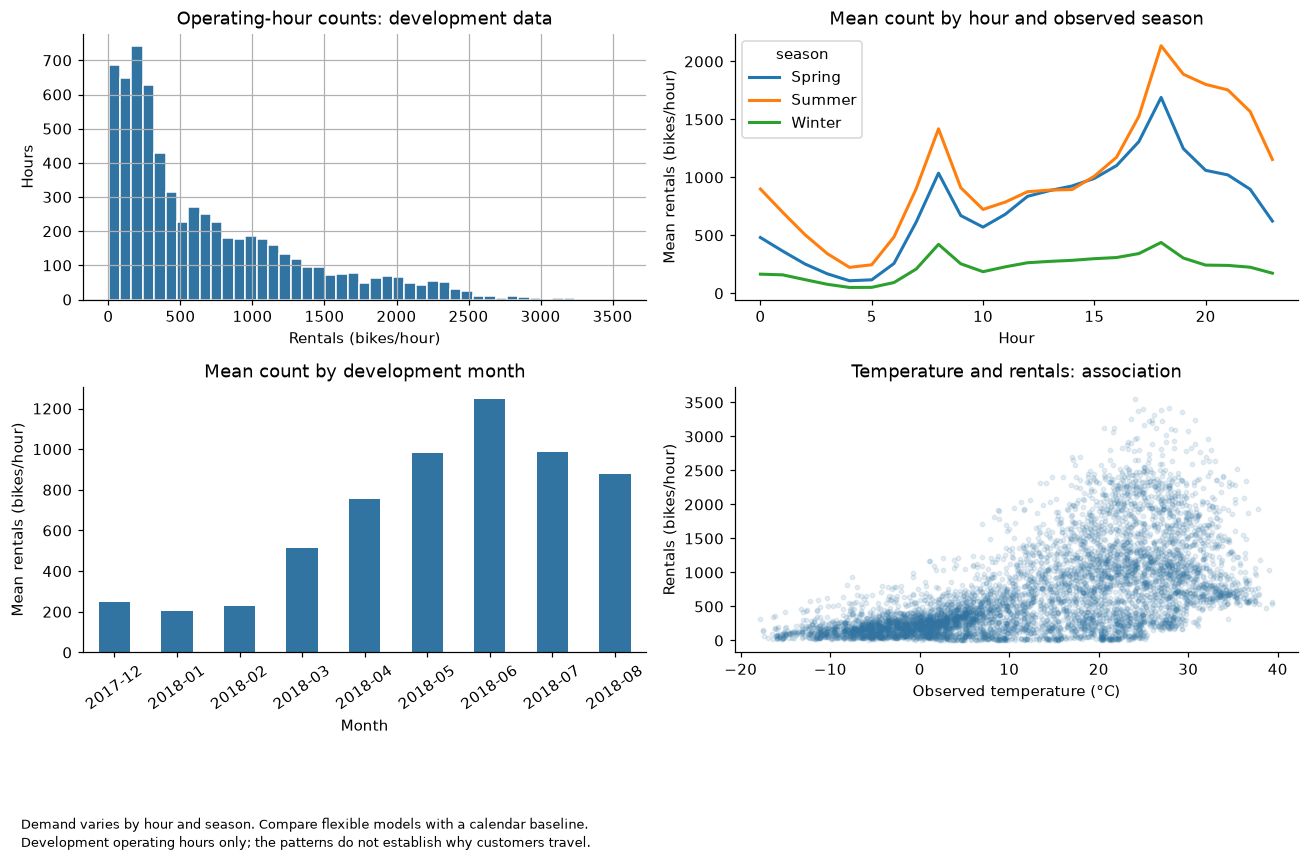

In [3]:
CUTOFF = pd.Timestamp("2018-09-01")
# operating preserves the open-hours population; train and test divide it by time.
operating = data.loc[data["functioning_day"].eq("Yes")].copy()
train = operating.loc[operating["timestamp"] < CUTOFF].copy()
test = operating.loc[operating["timestamp"] >= CUTOFF].copy()
assert train["timestamp"].max() < test["timestamp"].min()
assert len(train) + len(test) == len(operating)

split_summary = pd.DataFrame([
    {"population": name, "hours": len(part), "start": part["timestamp"].min(),
     "end": part["timestamp"].max(), "mean_rentals": part["rentals"].mean()}
    for name, part in [("Development: operating", train), ("Final test: operating", test),
                       ("Raw: all hours", data)]
])
display(split_summary)
split_summary.to_csv(artifact_path("split_summary.csv"), index=False)
WEATHER = ["temperature_c", "humidity_pct", "wind_speed_ms", "visibility_10m",
           "dew_point_c", "solar_radiation_mjm2", "rainfall_mm", "snowfall_cm"]
# Reuse train to calculate distribution flags without inspecting test outcomes.
quartiles = train[WEATHER].quantile([0.25, 0.75])
iqr = quartiles.loc[0.75] - quartiles.loc[0.25]
iqr_flags = ((train[WEATHER] < quartiles.loc[0.25] - 1.5 * iqr) |
             (train[WEATHER] > quartiles.loc[0.75] + 1.5 * iqr)).sum()
display(pd.DataFrame({"development_IQR_flags": iqr_flags, "rows_deleted": 0}))
display(train[["rentals"] + WEATHER].describe().round(2))

# Reuse train for all exploratory charts; these plots do not filter any rows.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
train["rentals"].hist(bins=45, ax=axes[0, 0], color="#3274a1", edgecolor="white")
axes[0, 0].set(title="Operating-hour counts: development data", xlabel="Rentals (bikes/hour)", ylabel="Hours")
hourly = train.groupby(["season", "hour"])["rentals"].mean().unstack(0)
hourly.plot(ax=axes[0, 1], linewidth=2)
axes[0, 1].set(title="Mean count by hour and observed season", xlabel="Hour", ylabel="Mean rentals (bikes/hour)")
monthly = train.groupby(train["date"].dt.to_period("M"))["rentals"].mean()
monthly.plot.bar(ax=axes[1, 0], color="#3274a1")
axes[1, 0].set(title="Mean count by development month", xlabel="Month", ylabel="Mean rentals (bikes/hour)")
axes[1, 0].tick_params(axis="x", rotation=35)
axes[1, 1].scatter(train["temperature_c"], train["rentals"], alpha=0.12, s=8, color="#3274a1")
axes[1, 1].set(title="Temperature and rentals: association", xlabel="Observed temperature (°C)", ylabel="Rentals (bikes/hour)")
fig.tight_layout()
save_figure("01_development_patterns.png", 'Demand varies by hour and season. Compare flexible models with a calendar baseline.\nDevelopment operating hours only; the patterns do not establish why customers travel.')

### Demand changes through the day and across observed seasons

The upper-left histogram shows many lower-count hours and a tail of high counts. The upper-right lines show different hourly profiles by season. The lower-left bars show the development-month variation, and the lower-right scatter shows a nonlinear temperature association. The largest pooled hourly mean is at 18:00, about 1,426 bikes/hour.

For planning, average demand alone will conceal busy periods. Compare a calendar baseline with models that can represent hourly and seasonal patterns, then inspect busy-hour errors before choosing a pilot.

These are descriptive development records, covering winter, spring and summer. They do not establish commuting behaviour, a causal weather effect or performance in the held-out autumn.

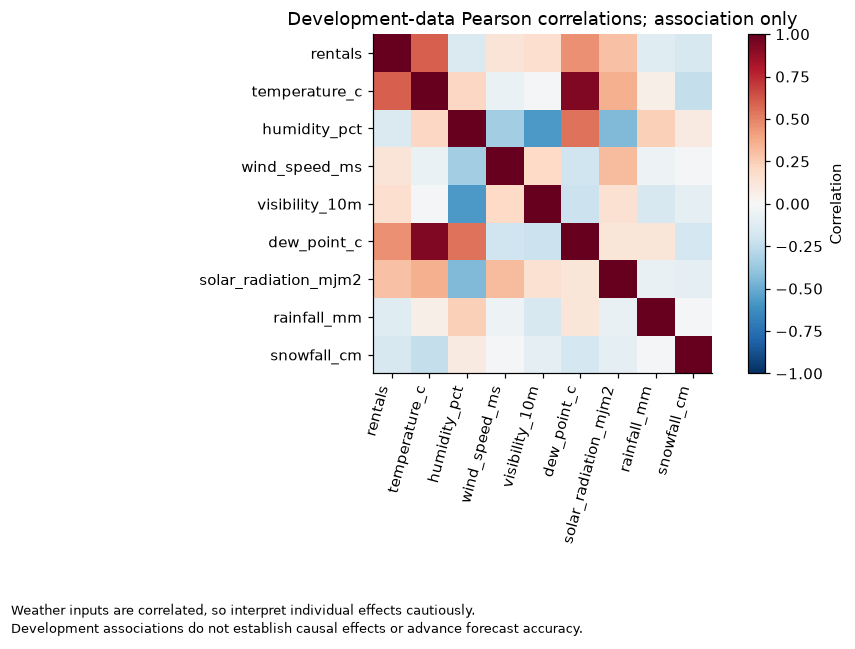

In [4]:
fig, ax = plt.subplots(figsize=(8, 6))
correlation = train[["rentals"] + WEATHER].corr()
im = ax.imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation)), correlation.columns, rotation=75, ha="right")
ax.set_yticks(range(len(correlation)), correlation.columns)
ax.set_title("Development-data Pearson correlations; association only")
fig.colorbar(im, ax=ax, label="Correlation")
save_figure("02_development_correlations.png", 'Weather inputs are correlated, so interpret individual effects cautiously.\nDevelopment associations do not establish causal effects or advance forecast accuracy.')

### Weather variables carry overlapping information

The heatmap shows pairwise associations in development operating hours. Rentals correlate positively with temperature (about 0.597), while several weather inputs also correlate with one another. Each cell describes a pair, not an adjusted effect.

For model review, correlated inputs limit how confidently individual coefficients or importance ranks can be explained. A predictive model can use them, but a claim that changing one weather variable would change rentals needs different evidence.

The heatmap uses Pearson correlation in development data. It neither measures causal effects nor verifies that future weather inputs are available at the planning horizon.

In [5]:
# profile and rainy summarise earlier training records for the interpretation below.
profile = train.groupby("hour")["rentals"].mean()
peak_hour = int(profile.idxmax())
rainy = train["rainfall_mm"].gt(0)
display(Markdown(
    f"**Development evidence:** {len(train):,} operating hours. The highest mean hourly count is at "
    f"{peak_hour:02d}:00 ({profile.max():,.0f} bikes/hour). Rain is recorded in {rainy.sum():,} hours; "
    f"mean counts are {train.loc[rainy, 'rentals'].mean():,.0f} during those hours and "
    f"{train.loc[~rainy, 'rentals'].mean():,.0f} otherwise. These comparisons are unadjusted associations. "
    "IQR flags are retained because rare weather conditions can be part of the intended population."
))

**Development evidence:** 6,528 operating hours. The highest mean hourly count is at 18:00 (1,426 bikes/hour). Rain is recorded in 429 hours; mean counts are 168 during those hours and 707 otherwise. These comparisons are unadjusted associations. IQR flags are retained because rare weather conditions can be part of the intended population.

## 2. Does a model improve the planning baseline?

The comparison uses one fixed population and timeline. Earlier data select the candidate; the autumn test is used once for the out-of-time check. Training-mean and hour-weekday rules represent simple alternatives. Lasso, kNN and Random Forest are the three source model families. The calendar-only forest is a separate availability sensitivity, not an option chosen after seeing test results.

The next cells construct the common inputs, fit transformations inside training folds, and freeze the candidate using earlier validation. This computation is needed before the business comparison; detailed settings are in the appendix.

In [6]:
def make_features(frame):
    # Build calendar features from each supplied frame while preserving its index.
    result = frame[WEATHER + ["hour", "season", "holiday"]].copy()
    result["weekday"] = frame["date"].dt.dayofweek
    month = frame["date"].dt.month
    result["month_sin"] = np.sin(2 * np.pi * (month - 1) / 12)
    result["month_cos"] = np.cos(2 * np.pi * (month - 1) / 12)
    return result

# X_train and X_test reuse the same feature function for every candidate model.
X_train, X_test = make_features(train), make_features(test)
y_train, y_test = train["rentals"], test["rentals"]
CALENDAR_NUMERIC = ["month_sin", "month_cos"]
CATEGORICAL = ["hour", "weekday", "season", "holiday"]
CATEGORIES = [list(range(24)), list(range(7)),
              ["Winter", "Spring", "Summer", "Autumn"], ["No Holiday", "Holiday"]]
NUMERIC = WEATHER + CALENDAR_NUMERIC
FEATURES = NUMERIC + CATEGORICAL
assert "rentals" not in X_train and "functioning_day" not in X_train
assert list(X_train.columns) == list(X_test.columns)

def preprocessing(include_weather=True):
    # The pipeline will fit this scaler and encoder on its training fold only.
    numeric = NUMERIC if include_weather else CALENDAR_NUMERIC
    return ColumnTransformer([
        ("numeric", StandardScaler(), numeric),
        ("categorical", OneHotEncoder(categories=CATEGORIES, handle_unknown="ignore",
                                      sparse_output=False), CATEGORICAL),
    ], remainder="drop")

class CalendarAverageRegressor(RegressorMixin, BaseEstimator):
    # Learn hour-by-weekday means from the supplied training fold only.
    def fit(self, X, y):
        table = X[["hour", "weekday"]].copy()
        table["rentals"] = np.asarray(y)
        self.means_ = table.groupby(["hour", "weekday"])["rentals"].mean()
        self.global_mean_ = float(np.mean(y))
        return self

    def predict(self, X):
        # Match new calendar keys to means learned during fit; use its fallback if absent.
        keys = pd.MultiIndex.from_frame(X[["hour", "weekday"]])
        return self.means_.reindex(keys).fillna(self.global_mean_).to_numpy()

def clipped_rmse(actual, predicted):
    return float(np.sqrt(mean_squared_error(actual, np.maximum(0, predicted))))

SCORER = make_scorer(clipped_rmse, greater_is_better=False)

In [7]:
# folds stores earlier/later row positions that GridSearchCV will reuse for all models.
folds, fold_records = [], []
for month in [6, 7, 8]:
    validation_start = pd.Timestamp(year=2018, month=month, day=1)
    validation_end = validation_start + pd.offsets.MonthBegin(1)
    earlier = np.flatnonzero((train["timestamp"] < validation_start - pd.Timedelta(days=1)).to_numpy())
    later = np.flatnonzero(((train["timestamp"] >= validation_start) &
                           (train["timestamp"] < validation_end)).to_numpy())
    assert len(earlier) and len(later)
    assert train.iloc[earlier]["timestamp"].max() < train.iloc[later]["timestamp"].min() - pd.Timedelta(days=1)
    folds.append((earlier, later))
    fold_records.append({"fold": len(folds), "training_hours": len(earlier), "validation_hours": len(later),
        "training_end": train.iloc[earlier]["timestamp"].max(),
        "validation_start": train.iloc[later]["timestamp"].min(),
        "validation_end": train.iloc[later]["timestamp"].max()})
fold_table = pd.DataFrame(fold_records)
display(fold_table)
fold_table.to_csv(artifact_path("validation_folds.csv"), index=False)

# estimators pairs each model pipeline with the settings searched on those folds.
estimators = {
    "Training mean": (DummyRegressor(strategy="mean"), {}),
    "Hour-weekday baseline": (CalendarAverageRegressor(), {}),
    "Lasso": (Pipeline([("preprocess", preprocessing()),
                         ("model", Lasso(max_iter=20000, tol=1e-4))]),
              {"model__alpha": [0.1, 1.0, 10.0, 30.0, 100.0]}),
    "kNN": (Pipeline([("preprocess", preprocessing()),
                       ("model", KNeighborsRegressor(n_jobs=2))]),
            {"model__n_neighbors": [5, 15, 30, 60], "model__weights": ["uniform", "distance"]}),
    "Random Forest": (Pipeline([("preprocess", preprocessing()),
                                ("model", RandomForestRegressor(n_estimators=160,
                                    random_state=SEED, n_jobs=2))]),
                      {"model__min_samples_leaf": [2, 8], "model__max_features": [0.6, 1.0]}),
    "Calendar-only RF (sensitivity)": (Pipeline([("preprocess", preprocessing(include_weather=False)),
                                  ("model", RandomForestRegressor(n_estimators=160,
                                      random_state=SEED, n_jobs=2))]),
                         {"model__min_samples_leaf": [2, 8], "model__max_features": [0.6, 1.0]}),
}
# searches retains fitted pipelines; cv_rows and tuning_tables retain validation evidence.
searches, cv_rows, tuning_tables = {}, [], []
for name, (estimator, grid) in estimators.items():
    search = GridSearchCV(estimator, grid, cv=folds, scoring=SCORER,
                          refit=True, n_jobs=1, error_score="raise", return_train_score=False)
    search.fit(X_train, y_train)
    searches[name] = search
    best = search.best_index_
    fold_errors = [-float(search.cv_results_[f"split{i}_test_score"][best]) for i in range(len(folds))]
    cv_rows.append({"model": name, "validation_rmse": -search.best_score_,
                    "fold_rmse_sd": float(np.std(fold_errors)),
                    "best_parameters": json.dumps(search.best_params_, sort_keys=True),
                    **{f"fold_{i+1}_rmse": value for i, value in enumerate(fold_errors)}})
    table = pd.DataFrame(search.cv_results_)
    table.insert(0, "model_name", name)
    tuning_tables.append(table)
    print(f"{name}: validation RMSE {(-search.best_score_):.2f}; {search.best_params_}")

cv_summary = pd.DataFrame(cv_rows).set_index("model").sort_values("validation_rmse")
primary_names = ["Training mean", "Hour-weekday baseline", "Lasso", "kNN", "Random Forest"]
# Select the candidate from validation scores before any final-test score is calculated.
selected_name = cv_summary.loc[primary_names, "validation_rmse"].idxmin()
best_ml_name = cv_summary.loc[["Lasso", "kNN", "Random Forest"], "validation_rmse"].idxmin()
selected_model = searches[selected_name].best_estimator_
cv_summary.to_csv(artifact_path("validation_scores.csv"))
pd.concat(tuning_tables, ignore_index=True).to_csv(artifact_path("tuning_results.csv"), index=False)
display(cv_summary.round(2))
display(Markdown(f"**Candidate frozen before test evaluation: {selected_name}.** "
                 f"Best ML family by development RMSE: {best_ml_name}."))

,fold,training_hours,validation_hours,training_end,validation_start,validation_end
0,1,4296,720,2018-05-30 23:00:00,2018-06-01,2018-06-30 23:00:00
1,2,5016,744,2018-06-29 23:00:00,2018-07-01,2018-07-31 23:00:00
2,3,5760,744,2018-07-30 23:00:00,2018-08-01,2018-08-31 23:00:00


Training mean: validation RMSE 825.23; {}
Hour-weekday baseline: validation RMSE 680.21; {}


Lasso: validation RMSE 566.01; {'model__alpha': 0.1}


kNN: validation RMSE 503.88; {'model__n_neighbors': 5, 'model__weights': 'distance'}


Random Forest: validation RMSE 410.69; {'model__max_features': 1.0, 'model__min_samples_leaf': 2}


Calendar-only RF (sensitivity): validation RMSE 524.13; {'model__max_features': 1.0, 'model__min_samples_leaf': 8}


,validation_rmse,fold_rmse_sd,best_parameters,fold_1_rmse,fold_2_rmse,fold_3_rmse
model,,,,,,
Random Forest,410.69,79.61,"{""model__max_features"": 1.0, ""model__min_sampl...",452.14,480.62,299.31
kNN,503.88,30.30,"{""model__n_neighbors"": 5, ""model__weights"": ""d...",499.66,542.93,469.07
Calendar-only RF (sensitivity),524.13,60.34,"{""model__max_features"": 1.0, ""model__min_sampl...",589.78,538.52,444.09
Lasso,566.01,81.77,"{""model__alpha"": 0.1}",560.47,668.82,468.75
Hour-weekday baseline,680.21,212.23,{},962.31,627.89,450.42
Training mean,825.23,193.68,{},1083.97,773.72,618.00


**Candidate frozen before test evaluation: Random Forest.** Best ML family by development RMSE: Random Forest.

,negative_predictions_clipped,rmse,mae,r2,mean_error_actual_minus_prediction,hours,rmse_improvement_vs_calendar_pct
model,,,,,,,
Random Forest,0,377.827,275.158,0.625,205.658,1937,21.658
Calendar-only RF (sensitivity),0,468.396,355.898,0.424,233.479,1937,2.879
Hour-weekday baseline,0,482.281,357.431,0.390,253.910,1937,0.000
kNN,0,552.797,420.016,0.198,307.094,1937,-14.621
Lasso,300,586.094,481.804,0.099,451.328,1937,-21.525
Training mean,0,667.141,513.888,-0.168,252.800,1937,-38.330


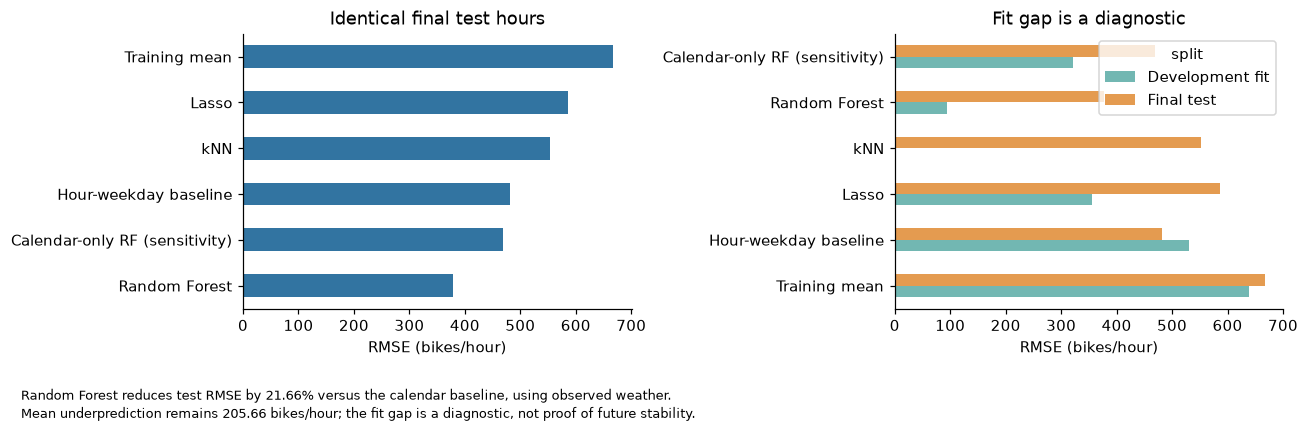

In [8]:
def metrics(actual, predicted):
    # Return errors in bikes/hour and check that the same residuals satisfy RMSE >= MAE.
    actual, predicted = np.asarray(actual), np.asarray(predicted)
    mae = float(mean_absolute_error(actual, predicted))
    rmse = float(np.sqrt(mean_squared_error(actual, predicted)))
    assert np.isfinite([mae, rmse]).all() and rmse + 1e-10 >= mae
    return {"rmse": rmse, "mae": mae, "r2": float(r2_score(actual, predicted)),
            "mean_error_actual_minus_prediction": float(np.mean(actual - predicted)),
            "hours": len(actual)}

# predictions aligns every model's test estimates with the same timestamps and outcomes.
predictions = pd.DataFrame({"timestamp": test["timestamp"].to_numpy(),
                            "actual_rentals": y_test.to_numpy(), "functioning_day": "Yes"})
evaluation_rows = []
for name, search in searches.items():
    # Reuse the pipeline refitted on development data; scoring never fits it again.
    estimator = search.best_estimator_
    for split, X, y in [("Development fit", X_train, y_train), ("Final test", X_test, y_test)]:
        raw_prediction = estimator.predict(X)
        prediction = np.maximum(0, raw_prediction)
        evaluation_rows.append({"model": name, "split": split,
                                "negative_predictions_clipped": int((raw_prediction < 0).sum()),
                                **metrics(y, prediction)})
        if split == "Final test":
            predictions[name] = prediction
# evaluation combines fit diagnostics and test scores; test_metrics keeps the final block.
evaluation = pd.DataFrame(evaluation_rows)
evaluation.to_csv(artifact_path("model_metrics.csv"), index=False)
predictions.to_csv(artifact_path("test_predictions.csv"), index=False)
test_metrics = evaluation.loc[evaluation["split"].eq("Final test")].drop(columns="split").set_index("model")
baseline_rmse = test_metrics.loc["Hour-weekday baseline", "rmse"]
test_metrics["rmse_improvement_vs_calendar_pct"] = 100 * (1 - test_metrics["rmse"] / baseline_rmse)
test_metrics.to_csv(artifact_path("final_test_comparison.csv"))
display(test_metrics.sort_values("rmse").round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
test_metrics["rmse"].sort_values().plot.barh(ax=axes[0], color="#3274a1")
axes[0].set(title="Identical final test hours", xlabel="RMSE (bikes/hour)", ylabel="")
comparison = evaluation.pivot(index="model", columns="split", values="rmse").loc[test_metrics.index]
comparison.plot.barh(ax=axes[1], color=["#72b7b2", "#e49b50"])
axes[1].set(title="Fit gap is a diagnostic", xlabel="RMSE (bikes/hour)", ylabel="")
fig.tight_layout()
save_figure("03_model_comparison.png", 'Random Forest reduces test RMSE by 21.66% versus the calendar baseline, using observed weather.\nMean underprediction remains 205.66 bikes/hour; the fit gap is a diagnostic, not proof of future stability.')

### Random Forest improves average error, with an operational caveat

The left panel compares every option on the same 1,937 test operating hours. Random Forest RMSE is 377.83 versus 482.28 for the hour-weekday rule, a 21.66% reduction. Its MAE is 275.16. The right panel compares fit and test RMSE; that gap flags possible overfitting or period shift. The calendar-only sensitivity has test RMSE 468.40.

The development-selected forest is the strongest conditional candidate in this comparison. Proceed to error-concentration review before an operational recommendation: its mean underprediction of 205.66 bikes/hour could matter when availability is being planned.

The model uses observed target-hour weather. One held-out autumn and a separately tuned calendar-only alternative do not establish a live forecast, forecast-weather performance or stable next-year accuracy. The test scores do not change the earlier candidate selection.

In [9]:
# chosen reads the preselected model's score; test_winner is a later diagnostic only.
chosen = test_metrics.loc[selected_name]
test_winner = test_metrics.loc[primary_names, "rmse"].idxmin()
calendar_sensitivity = test_metrics.loc["Calendar-only RF (sensitivity)"]
display(Markdown(
    f"**Measured final test:** the preselected {selected_name} records RMSE **{chosen['rmse']:,.2f}** and "
    f"MAE **{chosen['mae']:,.2f} bikes/hour**, across {len(test):,} operating hours. Its RMSE change "
    f"against the hour-weekday baseline is **{chosen['rmse_improvement_vs_calendar_pct']:+.1f}% improvement**. "
    f"The best primary option on this test window is {test_winner}; this is reported without revising selection. "
    f"The calendar-only forest records RMSE {calendar_sensitivity['rmse']:,.2f}. The difference between "
    "observed-weather and calendar-only performance does not measure the accuracy of a real weather forecast."
))

**Measured final test:** the preselected Random Forest records RMSE **377.83** and MAE **275.16 bikes/hour**, across 1,937 operating hours. Its RMSE change against the hour-weekday baseline is **+21.7% improvement**. The best primary option on this test window is Random Forest; this is reported without revising selection. The calendar-only forest records RMSE 468.40. The difference between observed-weather and calendar-only performance does not measure the accuracy of a real weather forecast.

## 3. Where could errors constrain the planning decision?

An aggregate accuracy gain can coexist with systematic underprediction and busy-hour misses. The following checks separate learned operating demand from known closed hours, then inspect test errors by time and condition. The closure rule is meaningful only if the schedule is known when a prediction is requested.

In [10]:
# all_test adds closed hours back; zero predictions implement the known-schedule assumption.
all_test = data.loc[data["timestamp"] >= CUTOFF].copy()
all_operating = all_test["functioning_day"].eq("Yes").to_numpy()
all_predictions = np.zeros(len(all_test))
all_predictions[all_operating] = np.maximum(0, selected_model.predict(make_features(all_test.loc[all_operating])))
all_metrics = {"model": selected_name, "population": "All hours; known closure schedule",
               "closed_hours": int((~all_operating).sum()), **metrics(all_test["rentals"], all_predictions)}
assert np.all(all_predictions[~all_operating] == 0)
assert np.all(all_test.loc[~all_operating, "rentals"] == 0)
(artifact_path("all_hours_metrics.json")).write_text(json.dumps(all_metrics, indent=2), encoding="utf-8")
display(pd.Series(all_metrics, name="result").to_frame())

# diagnostics reuses the selected test predictions to calculate residuals and segment errors.
diagnostics = test[["timestamp", "date", "hour", "rainfall_mm", "rentals"]].reset_index(drop=True)
diagnostics["prediction"] = predictions[selected_name].to_numpy()
diagnostics["residual"] = diagnostics["rentals"] - diagnostics["prediction"]
diagnostics["month"] = diagnostics["date"].dt.strftime("%Y-%m")
diagnostics["rain_status"] = np.where(diagnostics["rainfall_mm"] > 0, "Rain recorded", "No rain recorded")
segment_rows = []
for segment in ["month", "hour", "rain_status"]:
    for label, group in diagnostics.groupby(segment):
        segment_rows.append({"segment": segment, "label": str(label),
                             **metrics(group["rentals"], group["prediction"])})
segment_metrics = pd.DataFrame(segment_rows)
segment_metrics.to_csv(artifact_path("segment_metrics.csv"), index=False)
display(segment_metrics.loc[segment_metrics["segment"].ne("hour")].round(2))

# daily_error keeps candidate/baseline error totals paired within each test day.
daily_error = pd.DataFrame({"date": test["date"].to_numpy(),
    "candidate_squared_error": (y_test.to_numpy() - predictions[selected_name].to_numpy()) ** 2,
    "baseline_squared_error": (y_test.to_numpy() - predictions["Hour-weekday baseline"].to_numpy()) ** 2,
    "hours": 1}).groupby("date").sum()
rng = np.random.default_rng(SEED)
# Reuse daily totals in seeded resamples; each draw keeps all hours from its selected days.
resampled_days = rng.integers(0, len(daily_error), size=(1000, len(daily_error)))
sampled = daily_error.to_numpy()[resampled_days].sum(axis=1)
rmse_differences = np.sqrt(sampled[:, 1] / sampled[:, 2]) - np.sqrt(sampled[:, 0] / sampled[:, 2])
bootstrap_interval = np.quantile(rmse_differences, [0.025, 0.975])
bootstrap_result = {"comparison": "calendar_baseline_rmse_minus_candidate_rmse", "candidate": selected_name,
    "unit": "bikes/hour", "resampling_unit": "test day", "test_days": len(daily_error),
    "replicates": 1000, "seed": SEED,
    "observed_difference": float(baseline_rmse - chosen["rmse"]),
    "percentile_95_low": float(bootstrap_interval[0]), "percentile_95_high": float(bootstrap_interval[1]),
    "scope": "Descriptive resampling of autumn 2018; no future-period guarantee"}
(artifact_path("paired_day_bootstrap.json")).write_text(json.dumps(bootstrap_result, indent=2), encoding="utf-8")
display(pd.Series(bootstrap_result, name="result").to_frame())

,result
model,Random Forest
population,All hours; known closure schedule
closed_hours,247
rmse,355.820543
mae,244.03914
r2,0.701197
mean_error_actual_minus_prediction,182.39936
hours,2184


,segment,label,rmse,mae,r2,mean_error_actual_minus_prediction,hours
0,month,2018-09,310.51,215.20,0.80,69.91,624
1,month,2018-10,417.60,316.68,0.55,278.25,665
2,month,2018-11,393.58,290.29,0.25,261.89,648
27,rain_status,No rain recorded,384.40,281.90,0.60,216.26,1850
28,rain_status,Rain recorded,190.30,131.75,0.14,-19.87,87


,result
comparison,calendar_baseline_rmse_minus_candidate_rmse
candidate,Random Forest
unit,bikes/hour
resampling_unit,test day
test_days,81
replicates,1000
seed,123
observed_difference,104.454897
percentile_95_low,56.272109
percentile_95_high,155.068935


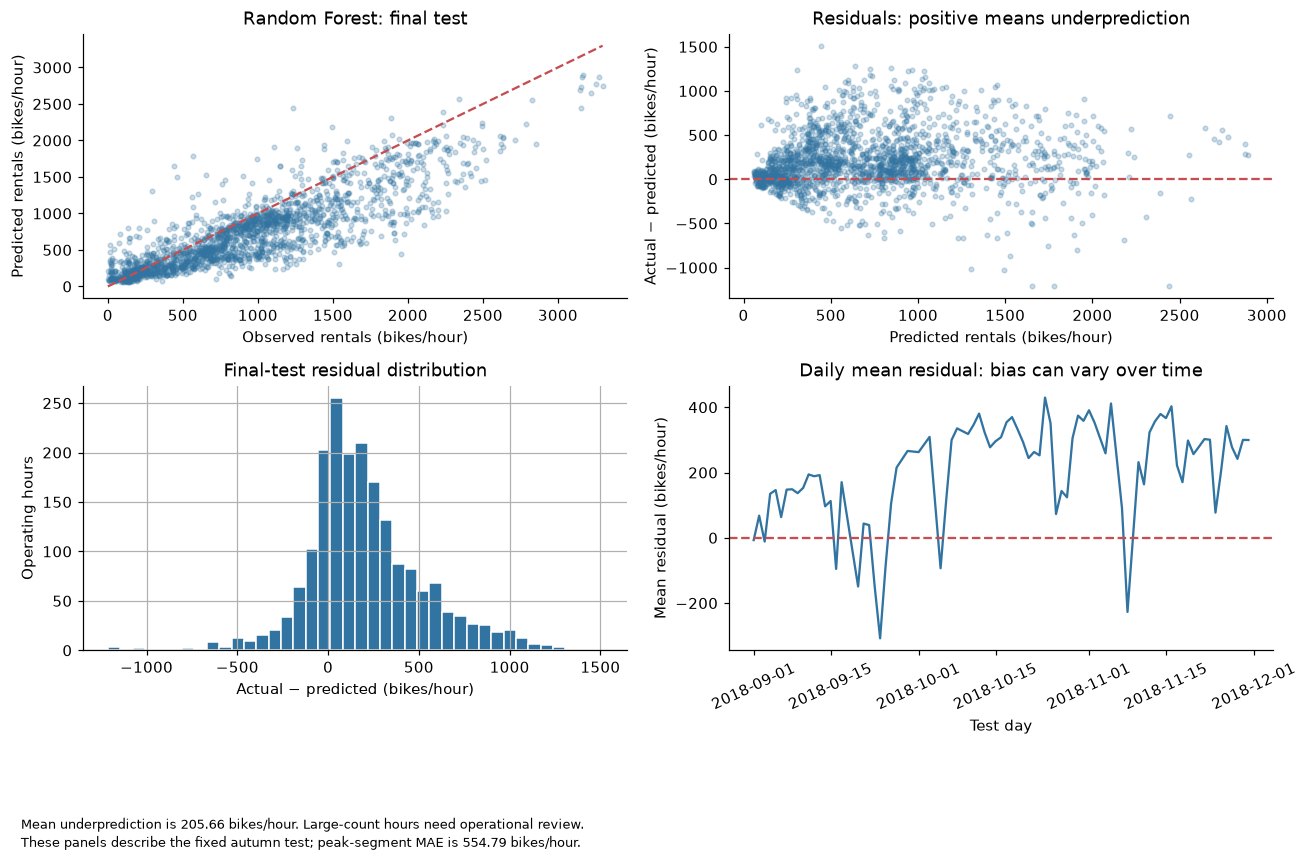

In [11]:
# Reuse diagnostics to show fit bias, residual spread and changes through the test period.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].scatter(diagnostics["rentals"], diagnostics["prediction"], s=9, alpha=0.25, color="#3274a1")
upper = max(diagnostics["rentals"].max(), diagnostics["prediction"].max())
axes[0, 0].plot([0, upper], [0, upper], color="#c44e52", linestyle="--")
axes[0, 0].set(title=f"{selected_name}: final test", xlabel="Observed rentals (bikes/hour)", ylabel="Predicted rentals (bikes/hour)")
axes[0, 1].scatter(diagnostics["prediction"], diagnostics["residual"], s=9, alpha=0.25, color="#3274a1")
axes[0, 1].axhline(0, color="#c44e52", linestyle="--")
axes[0, 1].set(title="Residuals: positive means underprediction", xlabel="Predicted rentals (bikes/hour)", ylabel="Actual − predicted (bikes/hour)")
diagnostics["residual"].hist(bins=40, ax=axes[1, 0], color="#3274a1", edgecolor="white")
axes[1, 0].set(title="Final-test residual distribution", xlabel="Actual − predicted (bikes/hour)", ylabel="Operating hours")
daily = diagnostics.groupby("date")["residual"].mean()
axes[1, 1].plot(daily.index, daily.values, color="#3274a1")
axes[1, 1].axhline(0, color="#c44e52", linestyle="--")
axes[1, 1].set(title="Daily mean residual: bias can vary over time", xlabel="Test day", ylabel="Mean residual (bikes/hour)")
axes[1, 1].tick_params(axis="x", rotation=25)
fig.tight_layout()
save_figure("04_residual_diagnostics.png", 'Mean underprediction is 205.66 bikes/hour. Large-count hours need operational review.\nThese panels describe the fixed autumn test; peak-segment MAE is 554.79 bikes/hour.')

### The candidate systematically understates parts of the test period

The upper-left panel compares actual and predicted counts with the equality line. The upper-right shows residuals against predictions; positive residuals mean underprediction. The lower-left shows their distribution, and the lower-right tracks daily mean residuals. Overall mean underprediction is 205.66 bikes/hour; monthly mean underprediction is about 69.91 in September, 278.25 in October and 261.89 in November.

For an availability decision, review persistent bias and large-count misses before using the model as a workload estimate. The retrospective high-demand segment has MAE 554.79, which limits the usefulness of the overall RMSE gain.

These diagnostics describe this autumn and are not predictive intervals. A high-demand segment is defined by realised test counts, so its membership would not be known before prediction. Normal residuals are not a requirement for tree predictions.

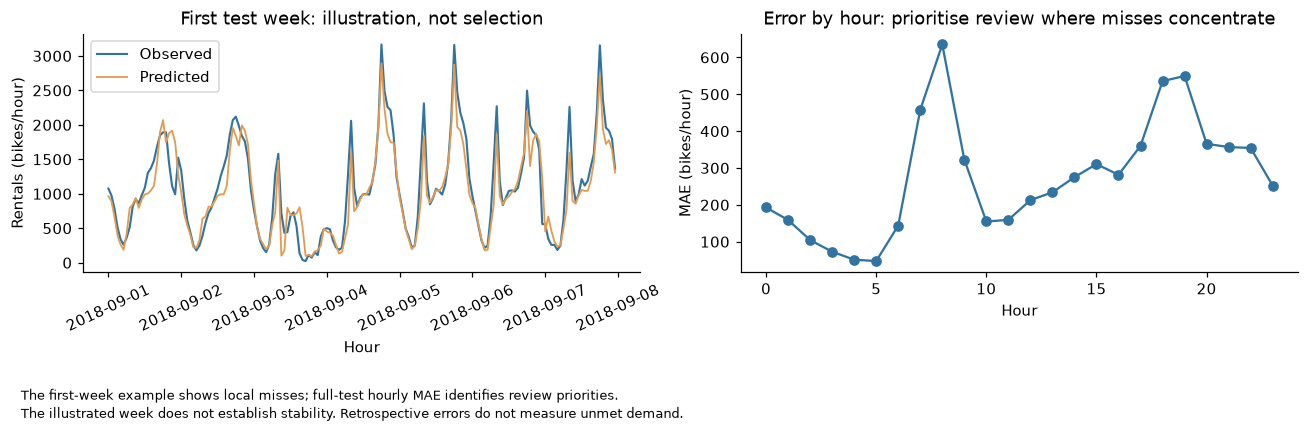

In [12]:
# preview selects a fixed first-week illustration; hour_errors reuses the full segment table.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
preview = diagnostics.loc[diagnostics["date"].between(pd.Timestamp("2018-09-01"), pd.Timestamp("2018-09-07"))]
axes[0].plot(preview["timestamp"], preview["rentals"], label="Observed", color="#3274a1", linewidth=1.4)
axes[0].plot(preview["timestamp"], preview["prediction"], label="Predicted", color="#e49b50", linewidth=1.2)
axes[0].set(title="First test week: illustration, not selection", xlabel="Hour", ylabel="Rentals (bikes/hour)")
axes[0].tick_params(axis="x", rotation=25)
axes[0].legend()
hour_errors = segment_metrics.loc[segment_metrics["segment"].eq("hour")].copy()
hour_errors["hour"] = hour_errors["label"].astype(int)
hour_errors.sort_values("hour").plot(x="hour", y="mae", ax=axes[1], legend=False, marker="o", color="#3274a1")
axes[1].set(title="Error by hour: prioritise review where misses concentrate", xlabel="Hour", ylabel="MAE (bikes/hour)")
fig.tight_layout()
save_figure("05_time_and_hour_errors.png", 'The first-week example shows local misses; full-test hourly MAE identifies review priorities.\nThe illustrated week does not establish stability. Retrospective errors do not measure unmet demand.')

### Review priorities vary by hour

The left panel overlays actual and predicted counts in the first fixed test week. It illustrates local misses. The right panel uses the full test period to show MAE by hour, identifying where average errors are concentrated.

Use the full-test hour breakdown to choose which periods need closer planning review. The first-week example makes the error tangible but should not determine the recommendation by itself.

The week was fixed as an illustration and is not a representative-sample claim. Completed rental counts and their prediction errors do not reveal unmet demand, station shortages or realised operating costs.

## 4. Which inputs create an operational dependency?

The fitted forest depends on hourly context and observed weather. Before calling it a planning forecast, verify which weather values would be available at the actual decision time. The next graph explains predictive dependence; it cannot estimate causal demand effects.

,feature,rmse_increase_mean,rmse_increase_sd
8,hour,282.06,9.41
0,temperature_c,172.93,8.00
5,solar_radiation_mjm2,129.41,4.90
1,humidity_pct,78.20,6.13
11,weekday,24.89,2.06
6,rainfall_mm,12.25,2.09
13,month_cos,7.79,1.14
4,dew_point_c,3.33,0.20
10,holiday,1.61,0.46
3,visibility_10m,0.85,1.09


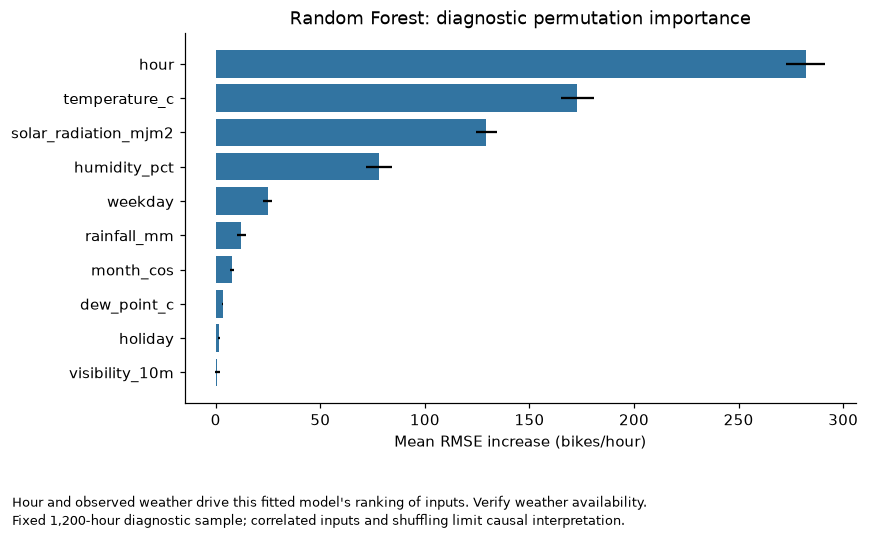

In [13]:
# importance_X fixes the diagnostic sample; importance_y matches labels by the same index.
importance_X = X_test.sample(n=min(1200, len(X_test)), random_state=SEED)
importance_y = y_test.loc[importance_X.index]
importance = permutation_importance(selected_model, importance_X, importance_y, scoring=SCORER,
                                    n_repeats=5, random_state=SEED, n_jobs=1)
importance_table = pd.DataFrame({"feature": X_test.columns,
    "rmse_increase_mean": importance.importances_mean,
    "rmse_increase_sd": importance.importances_std}).sort_values("rmse_increase_mean", ascending=False)
importance_table.to_csv(artifact_path("permutation_importance.csv"), index=False)
display(importance_table.round(2))
fig, ax = plt.subplots(figsize=(8, 5))
plot_importance = importance_table.head(10).sort_values("rmse_increase_mean")
ax.barh(plot_importance["feature"], plot_importance["rmse_increase_mean"],
        xerr=plot_importance["rmse_increase_sd"], color="#3274a1")
ax.set(title=f"{selected_name}: diagnostic permutation importance", xlabel="Mean RMSE increase (bikes/hour)")
save_figure("06_permutation_importance.png", "Hour and observed weather drive this fitted model's ranking of inputs. Verify weather availability.\nFixed 1,200-hour diagnostic sample; correlated inputs and shuffling limit causal interpretation.")

# Reuse the fitted Lasso pipeline to export its transformed feature names and coefficients.
lasso_pipeline = searches["Lasso"].best_estimator_
lasso_coefficients = pd.DataFrame({"transformed_feature": lasso_pipeline["preprocess"].get_feature_names_out(),
    "coefficient": lasso_pipeline["model"].coef_})
lasso_coefficients["absolute_coefficient"] = lasso_coefficients["coefficient"].abs()
lasso_coefficients.sort_values("absolute_coefficient", ascending=False).to_csv(artifact_path("lasso_coefficients.csv"), index=False)

### Hourly context and observed weather matter to this fitted model

The bars show the increase in RMSE after shuffling one input in a fixed 1,200-hour diagnostic sample. Hour has the largest mean increase (about 282.06 bikes/hour), followed by temperature (172.93) and solar radiation (129.41). Error bars describe variation across five shuffles.

For the next decision, prioritise verifying weather availability and evaluating real forecast-weather inputs at the intended horizon. Hour is known in advance; observed weather for the target hour is a different availability case.

Correlated inputs can substitute for one another, and shuffled combinations may be unrealistic. The sample and error bars describe this model diagnostic, not causal effects, economic benefits or confidence in future performance. The diagnostic does not retune the candidate.

## 5. Recommended next decision

Retain Random Forest as the candidate for further **conditional** demand testing. Its 21.66% RMSE improvement belongs alongside 205.66 bikes/hour mean underprediction and the high-demand MAE of 554.79. Resolve forecast-weather availability and busy-period error tolerance before recommending operational use.

Obtain another year and specify the planning horizon. Evaluate with weather forecasts available at each historical prediction time. Review peak-period misses against stakeholder-defined underprediction and overprediction costs. A citywide model also needs station-level inventory and movement data to support rebalancing decisions.

The dataset supplies no agreed acceptance threshold, operating costs or action owner. Savings, reduced shortages and production readiness are not measured. The next cell retains the calculated recommendation and uncertainty summary from the fixed experiment.

In [14]:
# Reuse chosen and baseline_rmse to state a recommendation from recorded scores.
better = chosen["rmse"] < baseline_rmse
candidate_is_ml = selected_name in ["Lasso", "kNN", "Random Forest"]
if candidate_is_ml and better:
    recommendation = (
        f"{selected_name} is a candidate for further weather-conditional testing: its held-out RMSE is "
        f"{100 * (1 - chosen['rmse'] / baseline_rmse):.1f}% below the calendar baseline. "
        "This supports further evaluation under an explicit input-availability contract, rather than deployment."
    )
elif candidate_is_ml:
    recommendation = (
        f"{selected_name} was selected by development validation but does not beat the calendar baseline "
        "on held-out RMSE. Retain the simpler baseline for the next comparison and investigate seasonal shift."
    )
else:
    recommendation = (
        f"The development protocol selected {selected_name}. The added model complexity did not establish "
        "a validation advantage under this protocol; use the baseline as the starting point for further evaluation."
    )
worst_hour = hour_errors.loc[hour_errors["mae"].idxmax()]
# peak_threshold comes from training counts; the test segment is retrospective diagnosis.
peak_threshold = float(y_train.quantile(0.90))
high_demand = diagnostics["rentals"].ge(peak_threshold)
peak_metrics = metrics(diagnostics.loc[high_demand, "rentals"], diagnostics.loc[high_demand, "prediction"])
display(Markdown(
    f"**Recommendation:** {recommendation}\n\n"
    f"**Error concentration:** test hour {int(worst_hour['label']):02d}:00 has the largest hourly MAE "
    f"({worst_hour['mae']:,.1f} bikes/hour, {int(worst_hour['hours'])} observations). "
    f"For {high_demand.sum():,} test hours above the development 90th-percentile count "
    f"({peak_threshold:,.0f}), MAE is {peak_metrics['mae']:,.1f} and mean actual-minus-predicted error is "
    f"{peak_metrics['mean_error_actual_minus_prediction']:,.1f} bikes/hour. The actual-count segment is "
    "a retrospective diagnostic; its membership would not be known before prediction.\n\n"
    f"**Comparison uncertainty:** the paired test-day bootstrap interval for baseline RMSE minus candidate "
    f"RMSE is [{bootstrap_interval[0]:,.1f}, {bootstrap_interval[1]:,.1f}] bikes/hour. "
    "Positive values favour the candidate within this test-period resampling assumption."
))

**Recommendation:** Random Forest is a candidate for further weather-conditional testing: its held-out RMSE is 21.7% below the calendar baseline. This supports further evaluation under an explicit input-availability contract, rather than deployment.

**Error concentration:** test hour 08:00 has the largest hourly MAE (635.0 bikes/hour, 81 observations). For 258 test hours above the development 90th-percentile count (1,646), MAE is 554.8 and mean actual-minus-predicted error is 541.1 bikes/hour. The actual-count segment is a retrospective diagnostic; its membership would not be known before prediction.

**Comparison uncertainty:** the paired test-day bootstrap interval for baseline RMSE minus candidate RMSE is [56.3, 155.1] bikes/hour. Positive values favour the candidate within this test-period resampling assumption.

## Technical appendix: evidence and evaluation details

### Evaluation contract

Run all cells in order from the project directory. Data paths are relative; no private university drive is required. The notebook writes plots, metrics, predictions, a data audit, and an execution manifest to `results/`.

The protocol is fixed before fitting:

| Item | Choice and reason |
|---|---|
| Grain and target | One Seoul system hour; rentals in that hour, in bikes/hour |
| Primary population | Hours where `functioning_day == "Yes"`; closure zeros are not ordinary operating demand |
| Final test window | 1 September to 30 November 2018; held out from preprocessing, tuning, and model-family selection |
| Development window | 1 December 2017 to 31 August 2018 |
| Validation | Three expanding monthly folds: June, July, August 2018; a one-day gap before each validation month |
| Tuning objective | Mean fold RMSE; negative predictions clipped to zero consistently in validation and final evaluation |
| Main baselines | Training mean and training hour-by-weekday mean; both fitted separately in every validation fold |
| Reported measures | RMSE, MAE, R², mean signed error, and improvement against the calendar baseline |
| Candidate selection | Lowest development-validation RMSE across the three ML families and the baselines |

RMSE weights large misses more strongly than MAE. Both remain in the target's original units. MAPE is omitted because the data include zero and very low counts. Train scores are fit diagnostics; final test scores are the out-of-time check. No model is retuned after inspecting the test results.

### Raw-data interpretation

The CSV is read with its original encoding and renamed to clear Python column names. `visibility_10m` remains in **10-metre units**; 2,000 means 20,000 metres. Zero rainfall, snowfall, and solar radiation are valid physical observations. A zero humidity value is retained and counted as a quality flag because the supplied metadata does not establish a replacement rule.

We check missing values, duplicate rows, duplicate timestamps, chronology, physical ranges, the closure status, and the target. Range checks detect suspicious records; they do not prove sensor accuracy. IQR flags are shown later as distribution diagnostics and do not trigger row deletion.

### Input availability and preprocessing

| Inputs | Available when? | Treatment |
|---|---|---|
| Hour, weekday, month, season, holiday | Calendar and published schedule can be known ahead of the hour | Included; month represented cyclically to respect December to January continuity |
| Operating status | Only if the service schedule is known | Defines the fitting population; explicit zero rule for closed hours |
| Temperature, humidity, wind, visibility, dew point, solar radiation, rain, snow | Dataset contains observations for the target hour | Included in conditional models; removed in the calendar-only sensitivity model |
| Target rentals or future rental counts | Outcome, unavailable for prediction | Never predictors |
| Date or timestamp identifier | Known, but risks learning one-year chronology without repeat-year evidence | Used for splitting and derived calendar features; excluded as an arbitrary numerical identifier |

All numeric scaling and categorical encoding live inside a scikit-learn pipeline. Each validation fit learns its own scaling parameters using earlier training observations. The feature-construction category lists are calendar/dataset definitions specified in advance, rather than values learned from the final test set. Neither target encoding nor target-derived lags are used.

Lasso offers a constrained linear comparison. kNN checks a local averaging approach and depends strongly on scaling. Random Forest can represent nonlinear responses and interactions. A reasonable model form does not guarantee that it will improve the baseline.

### Candidate selection

Each validation month is later than its training observations. A one-day gap reduces immediate adjacency between the two. It does not make hourly errors independent or remove seasonal shift. The monthly folds represent three historical development checks; their standard deviation is descriptive variation, not a confidence interval.

Hyperparameter grids are small, explicit choices for this portfolio experiment. Each validation month has equal weight in mean fold RMSE, although operating-hour counts differ slightly. The best settings are selected by the same mean validation RMSE as the baselines. Random Forest uses 160 trees and a fixed seed. The final test period is not used to choose the tree count, k, regularisation strength, or winning family.

The calendar-only forest is a separate, predeclared and independently tuned feature-availability sensitivity. It is not an isolated estimate of weather's contribution, because its selected settings may differ. It is not eligible to replace the selected primary candidate after test inspection.

### Final scoring

Every fitted option receives the identical September to November operating-hours test rows. Primary models use identical feature definitions and preprocessing; the calendar-only sensitivity intentionally omits weather. Predictions are clipped to zero because negative rental counts are infeasible; the number clipped is recorded.

The family chosen above remains the candidate even if a different family happens to score better on this one test period. Such a reversal is evidence of uncertainty and a reason to collect another evaluation period, rather than a reason to tune against this one.

### Closure reporting and descriptive uncertainty

For operational reporting, closed hours receive a zero prediction under an explicit known-schedule assumption. This changes the evaluation population and adds hours whose outcomes are structurally zero. The resulting all-hours error must not replace the operating-hours score when assessing learned demand prediction.

Errors are also broken down by test month, time of day, and rainy/dry hours. These segments are descriptive checks after evaluation and are not used to change the model. A paired bootstrap resamples whole test days to compare the selected candidate with the calendar baseline while keeping within-day error dependence. This treats days as independent resampling units and does not preserve dependence across days. Its percentile interval is descriptive uncertainty under resampling of this autumn period; it does not capture next-year shift, forecast-weather errors, or policy changes.

### Feature diagnostic limitations

The permutation-importance diagnostic is a post-evaluation diagnostic on a fixed, seeded sample of up to 1,200 final test hours. It measures how much the candidate's RMSE increases when one original input is shuffled, holding the fitted model and evaluation sample fixed. Correlated weather variables may substitute for one another; shuffling can also create unrealistic input combinations. Importance therefore describes this model's predictive dependence in this period, rather than a causal effect or a deployment policy.

The diagnostic is not used to drop features, retune, or change the selected candidate. Lasso coefficients are also available in `.generated/lasso_coefficients.csv` for model review; scaling makes their numerical interpretation differ from original-unit effects.

### Additional solution and operational limits

The business recommendation uses the recorded model metrics. It separates predictive performance from business value. A model that reduces average error can still miss busy hours, underpredict peaks, or fail during a new operating policy.

**Solution limitations:** only one year of aggregated counts; a single held-out autumn; observed weather; no calibrated prediction intervals; model extrapolation and seasonal drift; pooled hourly metrics can conceal peak-period errors. Completed rentals may be constrained by available bikes, so they do not measure all unmet demand.

**Operational unknowns:** station inventory, trip origins and destinations, staffing and rebalancing costs, tolerable under/overprediction, actual weather forecasts at the decision horizon, published closure schedules, and current service conditions are not supplied. Financial savings, causal effects, and production readiness are therefore not estimated.

**Proposed next steps:** obtain a second year and the intended prediction horizon; evaluate with forecast weather available at each historical planning time; review peak-hour and adverse-weather errors against stakeholder-defined costs; compare a pilot with the existing planning rule; monitor drift and retain a fallback. These are recommendations, not approved actions or assigned owners.

### Source-review corrections and execution evidence

| Source issue | Python correction | Why it changes the evidence |
|---|---|---|
| kNN scaling was calculated before the time split | Pipeline fits scaling inside each development fold and full-training refit | Test distributions do not influence learned preprocessing |
| kNN k was selected using the final test outcomes | All parameter grids use earlier monthly validation folds | The final window remains an independent evaluation check |
| Lasso used ordinary random cross-validation | Expanding chronological validation with a one-day gap | Respects the direction of the operational prediction task |
| Source reported RF test RMSE 65.05 and MAE 104.61 | Recompute metrics from saved predictions; assert RMSE ≥ MAE | The source pair cannot describe the same residuals; no source score is reused |
| Other source paragraphs give conflicting RF scores and unsupported stability claims | Report current computed scores and a limited period-specific bootstrap | A reproducible result has an explicit population and uncertainty boundary |
| Source visibility interpreted in metres | Preserve the documented `10m` unit | Avoid a tenfold interpretation error |
| Source appendix contains a blank functioning-day filter in one version | Audit actual `Yes`/`No` values and derive the operating subset | Prevent empty or unintended model populations |
| Prediction described as forecasting with same-hour observed weather | Separate conditional prediction from calendar-only sensitivity and future forecast evaluation | Avoid claiming information available before it exists |
| Possible blanket outlier treatment | Retain all raw rows and show distribution flags only | Rare weather remains represented without an unsupported deletion rule |

The package README documents rerunning and attribution. Dataset provenance is in `data/README.md` and `data/provenance.json`. The final verification assertions validate chronology, metric consistency, and nonnegative predictions. They establish execution and internal consistency, not suitability for production or economic value.

Method references: [scikit-learn data leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage), [time-aware cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-of-time-series-data), and the [UCI dataset metadata](https://archive.ics.uci.edu/dataset/560/seoul+bike+sharing+demand).

### How the original descriptive notes were retained

The group report's Part 1 discussion supplied ideas for the current demand-pattern and correlation graphs. The right-skewed count distribution, variation by hour and observed season, and weather associations are retained beside those graphs as descriptive findings in the current development population.

The original commuting explanation is a hypothesis and is not carried forward as a cause. The report's exact temperature plateau near 25°C is omitted because the current scatter does not estimate such a breakpoint. Standalone weekday and holiday conclusions are also omitted: the selected graphs do not quantify those comparisons separately, and no causal effect is established. Rare weather values remain in the raw data; distribution flags do not authorise deletion.

In [15]:
# Reuse saved arrays and fold positions to check consistency before marking completion.
assert len(predictions) == len(test)
assert np.isfinite(predictions[list(searches)].to_numpy()).all()
assert (predictions[list(searches)].to_numpy() >= 0).all()
assert (evaluation["rmse"] + 1e-10 >= evaluation["mae"]).all()
assert all(train.iloc[a]["timestamp"].max() < train.iloc[b]["timestamp"].min() for a, b in folds)
assert len(raw) == len(data) and len(train) + len(test) == 8465
assert set(X_train.columns).isdisjoint({"rentals", "timestamp", "date", "functioning_day"})

# manifest records the measured run, its dependencies, and the interpretation above.
manifest = {
    "status": "executed_successfully", "started_at_utc": STARTED_AT,
    "completed_at_utc": datetime.now(timezone.utc).isoformat(),
    "elapsed_seconds": round(time.perf_counter() - STARTED_TIMER, 2),
    "python_version": platform.python_version(), "dependencies": VERSIONS,
    "seed": SEED, "dataset_sha256": DATA_SHA256,
    "raw_rows_retained": len(raw), "operating_development_hours": len(train),
    "operating_test_hours": len(test), "all_test_hours": len(all_test),
    "selected_by_validation": selected_name, "best_ml_by_validation": best_ml_name,
    "final_test_winner_descriptive_only": test_winner,
    "selected_test_metrics": {k: float(v) for k, v in chosen.items()},
    "recommendation": recommendation,
    "peak_hour_diagnostic": peak_metrics,
    "assertions_passed": ["raw rows preserved", "dataset SHA-256", "hourly chronology",
        "duplicate and missing audit", "train before test", "validation after training",
        "outcome absent from features", "nonnegative predictions", "RMSE >= MAE"],
    "scope": "Historical conditional prediction; no measured deployment benefit",
}
(artifact_path("execution_details.json")).write_text(json.dumps(manifest, indent=2), encoding="utf-8")
(artifact_path("model_metrics.json")).write_text(json.dumps(evaluation_rows, indent=2), encoding="utf-8")
print(f"Execution complete. Candidate: {selected_name}. Artifacts: {RESULTS.name}/")
print(f"Raw rows preserved: {len(raw):,}; all methodological assertions passed.")

Execution complete. Candidate: Random Forest. Artifacts: results/
Raw rows preserved: 8,760; all methodological assertions passed.
